# Create the VAE class

In [58]:
from collections import namedtuple
import torch
import torch.nn as nn

VAEOutput = namedtuple("VAEOutput",
                       ["output", "codings_mean", "codings_logvar"])

class VAE(nn.Module):
    def __init__(self, codings_dim=32):
        super(VAE, self).__init__()
        self.codings_dim = codings_dim
        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(1 * 28 * 28, 128), nn.ReLU(),
            nn.Linear(128, 2 * codings_dim))  # output both the mean and logvar
        self.decoder = nn.Sequential(
            nn.Linear(codings_dim, 128), nn.ReLU(),
            nn.Linear(128, 1 * 28 * 28), nn.Sigmoid(),
            nn.Unflatten(dim=1, unflattened_size=(1, 28, 28)))

    def encode(self, X):
        return self.encoder(X).chunk(2, dim=-1)  # returns (mean, logvar)

    def sample_codings(self, codings_mean, codings_logvar):
        codings_std = torch.exp(0.5 * codings_logvar)
        noise = torch.randn_like(codings_std)
        return codings_mean + noise * codings_std

    def decode(self, Z):
        return self.decoder(Z)

    def forward(self, X):
        codings_mean, codings_logvar = self.encode(X)
        codings = self.sample_codings(codings_mean, codings_logvar)
        output = self.decode(codings)
        return VAEOutput(output, codings_mean, codings_logvar)

# Define the VAE loss function

In [59]:
import torch.nn.functional as F

def vae_loss(y_pred, y_target, kl_weight=1.0):
    output, mean, logvar = y_pred
    kl_div = -0.5 * torch.sum(1 + logvar - logvar.exp() - mean.square(), dim=-1)
    return F.mse_loss(output, y_target) + kl_weight * kl_div.mean() / 784

# Load the data and create the loaders

In [60]:
import numpy as np
import torch
import urllib.request
from torch.utils.data import DataLoader, TensorDataset, random_split

# Download the cat category (~100 MB, 120k+ drawings)
url = "https://storage.googleapis.com/quickdraw_dataset/full/numpy_bitmap/cat.npy"
urllib.request.urlretrieve(url, "cat.npy")

data = np.load("cat.npy")                       # shape: (N, 784), uint8
print(data.shape)

# Scale to [0, 1] and reshape to (N, 1, 28, 28), like MNIST after ToTensor()
X = torch.from_numpy(data).float().div(255).view(-1, 1, 28, 28)

# Optional: keep a subset so epochs are about as fast as MNIST
X = X[:60000]

# Dummy labels keep the (x, label) format your AutoencoderDataset expects
full_dataset = TensorDataset(X, torch.zeros(len(X)))

train_dataset, valid_dataset = random_split(
    full_dataset,
    [len(X) - 5000, 5000],
    generator=torch.Generator().manual_seed(42)
)

from torch.utils.data import Dataset

class AutoencoderDataset(Dataset):
    def __init__(self, base_dataset):
        self.base_dataset = base_dataset

    def __len__(self):
        return len(self.base_dataset)

    def __getitem__(self, idx):
        x, _ = self.base_dataset[idx]
        return x, x

train_loader = DataLoader(AutoencoderDataset(train_dataset), batch_size=128,
                          shuffle=True)
valid_loader = DataLoader(AutoencoderDataset(valid_dataset), batch_size=128)

(123202, 784)


# Define the training function

In [61]:
import torchmetrics

def evaluate_tm(model, data_loader, metric):
    model.eval()
    metric.reset()
    with torch.no_grad():
        for X_batch, y_batch in data_loader:
            X_batch, y_batch = X_batch.to("cuda"), y_batch.to("cuda")
            y_pred = model(X_batch)
            if isinstance(y_pred, tuple):
                y_pred = y_pred.output
            metric.update(y_pred, y_batch)
    return metric.compute()

def train(model, optimizer, loss_fn, metric, train_loader, valid_loader,
          n_epochs, patience=2, factor=0.5, epoch_callback=None):
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="max", patience=patience, factor=factor)
    history = {"train_losses": [], "train_metrics": [], "valid_metrics": []}
    for epoch in range(n_epochs):
        total_loss = 0.0
        metric.reset()
        model.train()
        if epoch_callback is not None:
            epoch_callback(model, epoch)
        for index, (X_batch, y_batch) in enumerate(train_loader):
            X_batch, y_batch = X_batch.to("cuda"), y_batch.to("cuda")
            y_pred = model(X_batch)

            #print("Input shape:", X_batch.shape)
            #print("Prediction shape:", y_pred.shape)
            #print("Target shape:", y_batch.shape)

            loss = loss_fn(y_pred, y_batch)
            total_loss += loss.item()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            optimizer.zero_grad()
            if isinstance(y_pred, tuple):
                y_pred = y_pred.output
            metric.update(y_pred, y_batch)
            train_metric = metric.compute().item()
            print(f"\rBatch {index + 1}/{len(train_loader)}", end="")
            print(f", loss={total_loss/(index+1):.4f}", end="")
            print(f", {train_metric=:.3f}", end="")
        history["train_losses"].append(total_loss / len(train_loader))
        history["train_metrics"].append(train_metric)
        val_metric = evaluate_tm(model, valid_loader, metric).item()
        history["valid_metrics"].append(val_metric)
        scheduler.step(val_metric)
        print(f"\rEpoch {epoch + 1}/{n_epochs},                      "
              f"train loss: {history['train_losses'][-1]:.4f}, "
              f"train metric: {history['train_metrics'][-1]:.3}, "
              f"valid metric: {history['valid_metrics'][-1]:.3}")
    return history

# Train the VAE

In [62]:
torch.manual_seed(42)
vae = VAE().to("cuda")
optimizer = torch.optim.NAdam(vae.parameters(), lr=1e-3)
rmse = torchmetrics.MeanSquaredError(squared=False).to("cuda")
history = train(vae, optimizer, vae_loss, rmse, train_loader, valid_loader,
                n_epochs=20)

Epoch 1/20,                      train loss: 0.0984, train metric: 0.306, valid metric: 0.287
Epoch 2/20,                      train loss: 0.0863, train metric: 0.282, valid metric: 0.276
Epoch 3/20,                      train loss: 0.0832, train metric: 0.272, valid metric: 0.268
Epoch 4/20,                      train loss: 0.0814, train metric: 0.266, valid metric: 0.264
Epoch 5/20,                      train loss: 0.0803, train metric: 0.263, valid metric: 0.261
Epoch 6/20,                      train loss: 0.0798, train metric: 0.261, valid metric: 0.26
Epoch 7/20,                      train loss: 0.0794, train metric: 0.26, valid metric: 0.259
Epoch 8/20,                      train loss: 0.0790, train metric: 0.259, valid metric: 0.258
Epoch 9/20,                      train loss: 0.0789, train metric: 0.258, valid metric: 0.257
Epoch 10/20,                      train loss: 0.0787, train metric: 0.257, valid metric: 0.257
Epoch 11/20,                      train loss: 0.0786, train m

# Visualize the reconstructions

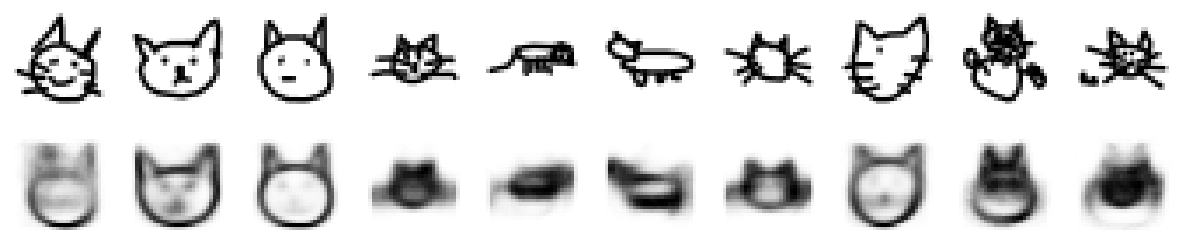

In [63]:
import matplotlib.pyplot as plt

def plot_image(image):
    plt.imshow(image.permute(1, 2, 0).cpu(), cmap="binary")
    plt.axis("off")

def plot_reconstructions(model, images, n_images=10):
    images = images[:n_images]
    with torch.no_grad():
        y_pred = model(images.to("cuda"))
    if isinstance(y_pred, tuple):
        y_pred = y_pred.output
    fig = plt.figure(figsize=(len(images) * 1.5, 3))
    for idx in range(len(images)):
        plt.subplot(2, len(images), 1 + idx)
        plot_image(images[idx])
        plt.subplot(2, len(images), 1 + len(images) + idx)
        plot_image(y_pred[idx])

X_valid = torch.stack([x for x, _ in valid_dataset])

torch.manual_seed(42)
plot_reconstructions(vae, X_valid)

plt.show()

# Generate Cat images

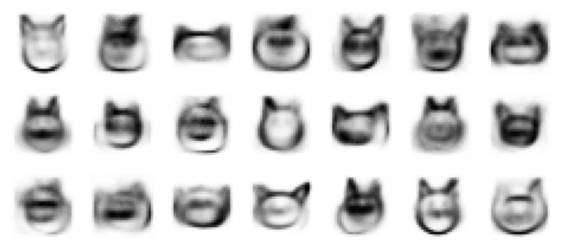

In [69]:
torch.manual_seed(42)  # extra code – ensures reproducibility

vae.eval()
codings = torch.randn(3 * 7, vae.codings_dim, device="cuda")
with torch.no_grad():
    images = vae.decode(codings)

def plot_multiple_images(images, n_cols=None):
    n_cols = n_cols or len(images)
    n_rows = (len(images) - 1) // n_cols + 1
    plt.figure(figsize=(n_cols, n_rows))
    for index, image in enumerate(images):
        plt.subplot(n_rows, n_cols, index + 1)
        plot_image(image)

plot_multiple_images(images, 7)

plt.show()